# Diabetes Prediction

In [1]:
# Import required libraries

import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

#visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model evaluation metrics to measure classifier performance
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

## Load the dataset

In [2]:
# Load the datasets
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

In [4]:
train_df.head()

,id,age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,bmi,waist_to_hip_ratio,systolic_bp,...,gender,ethnicity,education_level,income_level,smoking_status,employment_status,family_history_diabetes,hypertension_history,cardiovascular_history,diagnosed_diabetes
0,0,31,1,45,7.7,6.8,6.1,33.4,0.93,112,...,Female,Hispanic,Highschool,Lower-Middle,Current,Employed,0,0,0,1.0
1,1,50,2,73,5.7,6.5,5.8,23.8,0.83,120,...,Female,White,Highschool,Upper-Middle,Never,Employed,0,0,0,1.0
2,2,32,3,158,8.5,7.4,9.1,24.1,0.83,95,...,Male,Hispanic,Highschool,Lower-Middle,Never,Retired,0,0,0,0.0
3,3,54,3,77,4.6,7.0,9.2,26.6,0.83,121,...,Female,White,Highschool,Lower-Middle,Current,Employed,0,1,0,1.0
4,4,54,1,55,5.7,6.2,5.1,28.8,0.90,108,...,Male,White,Highschool,Upper-Middle,Never,Retired,0,1,0,1.0


## Exploratory Data Analysis (EDA)

In [4]:
train_df.shape

(700000, 26)

In [5]:
test_df.shape

(300000, 25)

In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700000 entries, 0 to 699999
Data columns (total 26 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   id                                  700000 non-null  int64  
 1   age                                 700000 non-null  int64  
 2   alcohol_consumption_per_week        700000 non-null  int64  
 3   physical_activity_minutes_per_week  700000 non-null  int64  
 4   diet_score                          700000 non-null  float64
 5   sleep_hours_per_day                 700000 non-null  float64
 6   screen_time_hours_per_day           700000 non-null  float64
 7   bmi                                 700000 non-null  float64
 8   waist_to_hip_ratio                  700000 non-null  float64
 9   systolic_bp                         700000 non-null  int64  
 10  diastolic_bp                        700000 non-null  int64  
 11  heart_rate                

In [5]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,700000.0,349999.500000,202072.738554,0.00,174999.75,349999.50,524999.25,699999.00
age,700000.0,50.359734,11.655520,19.00,42.00,50.00,58.00,89.00
alcohol_consumption_per_week,700000.0,2.072411,1.048189,1.00,1.00,2.00,3.00,9.00
physical_activity_minutes_per_week,700000.0,80.230803,51.195071,1.00,49.00,71.00,96.00,747.00
diet_score,700000.0,5.963695,1.463336,0.10,5.00,6.00,7.00,9.90
sleep_hours_per_day,700000.0,7.002200,0.901907,3.10,6.40,7.00,7.60,9.90
screen_time_hours_per_day,700000.0,6.012733,2.022707,0.60,4.60,6.00,7.40,16.50
bmi,700000.0,25.874684,2.860705,15.10,23.90,25.90,27.80,38.40
waist_to_hip_ratio,700000.0,0.858766,0.037980,0.68,0.83,0.86,0.88,1.05
systolic_bp,700000.0,116.294193,11.010390,91.00,108.00,116.00,124.00,163.00


In [6]:
print("\nMissing Values in Training Data:")
print(train_df.isnull().sum())


Missing Values in Training Data:
id                                    0
age                                   0
alcohol_consumption_per_week          0
physical_activity_minutes_per_week    0
diet_score                            0
sleep_hours_per_day                   0
screen_time_hours_per_day             0
bmi                                   0
waist_to_hip_ratio                    0
systolic_bp                           0
diastolic_bp                          0
heart_rate                            0
cholesterol_total                     0
hdl_cholesterol                       0
ldl_cholesterol                       0
triglycerides                         0
gender                                0
ethnicity                             0
education_level                       0
income_level                          0
smoking_status                        0
employment_status                     0
family_history_diabetes               0
hypertension_history                  0
cardio

In [7]:
# Check duplicate rows
print(f"Total duplicate rows: {train_df.duplicated().sum()}")

Total duplicate rows: 0


In [8]:
print("\n====================")
print("TARGET ANALYSIS")
print("====================")

target_counts = train_df["diagnosed_diabetes"].value_counts()
target_ratio = train_df["diagnosed_diabetes"].mean()

print("\nTarget distribution:\n", target_counts)
print(f"Positive rate (diabetes=1): {target_ratio:.4f}")


TARGET ANALYSIS

Target distribution:
 diagnosed_diabetes
1.0    436307
0.0    263693
Name: count, dtype: int64
Positive rate (diabetes=1): 0.6233



===== TARGET VARIABLE ANALYSIS =====


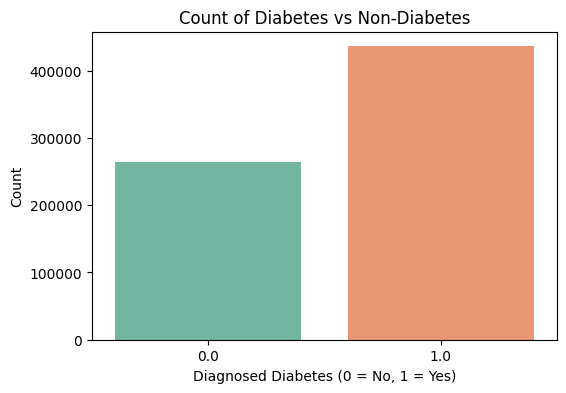

In [9]:
# Target Variable Analysis
print("\n===== TARGET VARIABLE ANALYSIS =====")

plt.figure(figsize=(6, 4))
sns.countplot(x="diagnosed_diabetes", data=train_df, palette="Set2")
plt.title("Count of Diabetes vs Non-Diabetes")
plt.xlabel("Diagnosed Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

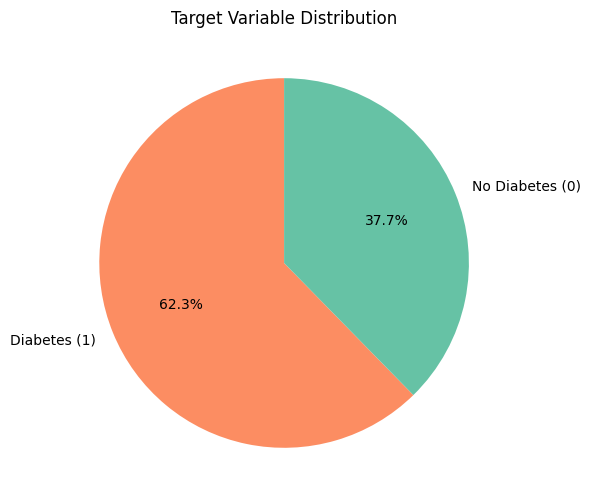

In [13]:
# Pie chart
target_counts = train_df["diagnosed_diabetes"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(
    target_counts,
    labels=["Diabetes (1)", "No Diabetes (0)"],
    autopct="%1.1f%%",
    colors=["#fc8d62", "#66c2a5"],
    startangle=90
)
plt.title("Target Variable Distribution")
plt.show()

In [15]:
# Identify Numeric & Categorical Columns
# -----------------------------
categorical_cols = train_df.select_dtypes(include=['object']).columns.tolist()
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()

# Remove ID and target from numeric list
numeric_cols = [col for col in numeric_cols if col not in ["id", "diagnosed_diabetes"]]

print("\n===== COLUMN CATEGORIZATION =====")
print("\nNumeric Columns:")
print(", ".join(numeric_cols))

print("\nCategorical Columns:")
print(", ".join(categorical_cols))


===== COLUMN CATEGORIZATION =====

Numeric Columns:
age, alcohol_consumption_per_week, physical_activity_minutes_per_week, diet_score, sleep_hours_per_day, screen_time_hours_per_day, bmi, waist_to_hip_ratio, systolic_bp, diastolic_bp, heart_rate, cholesterol_total, hdl_cholesterol, ldl_cholesterol, triglycerides, family_history_diabetes, hypertension_history, cardiovascular_history

Categorical Columns:
gender, ethnicity, education_level, income_level, smoking_status, employment_status



===== NUMERIC FEATURE DISTRIBUTIONS =====


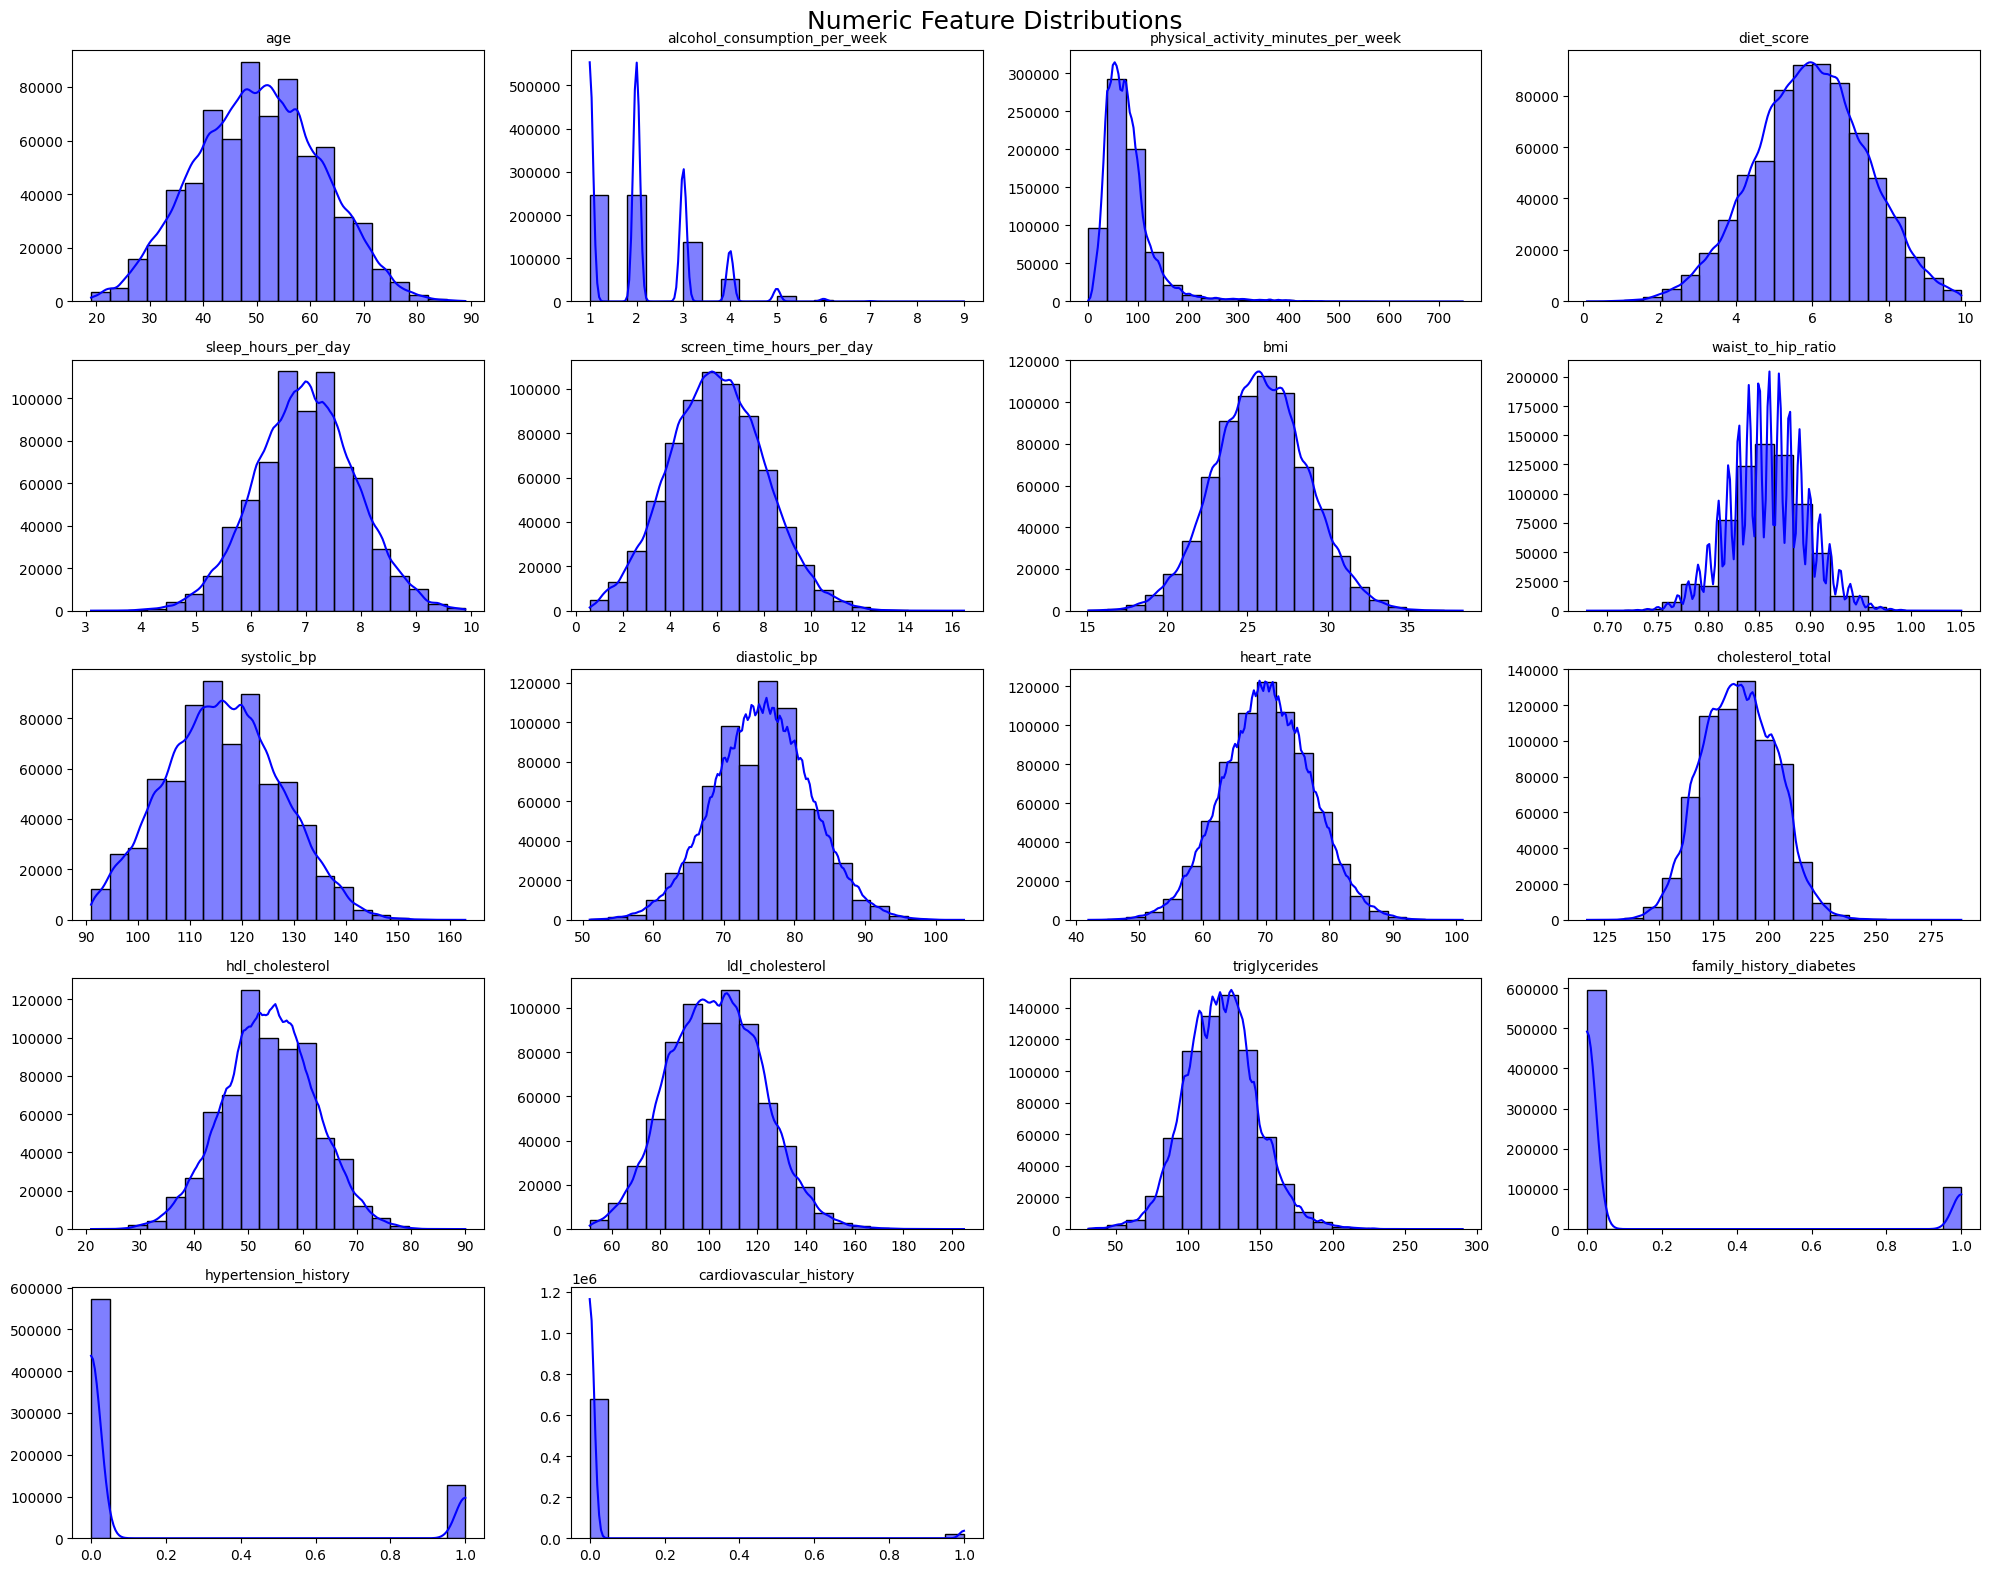

In [16]:
# -----------------------------
# Numeric Feature Distributions
# -----------------------------
print("\n===== NUMERIC FEATURE DISTRIBUTIONS =====")

fig, axes = plt.subplots(5, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(train_df[col], kde=True, ax=axes[i], color="blue", bins=20)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

# Hide unused subplots if numeric_cols < 20
for j in range(len(numeric_cols), 20):
    axes[j].axis("off")

plt.suptitle("Numeric Feature Distributions", fontsize=18)
plt.tight_layout()
plt.show()


===== CATEGORICAL FEATURE DISTRIBUTIONS =====


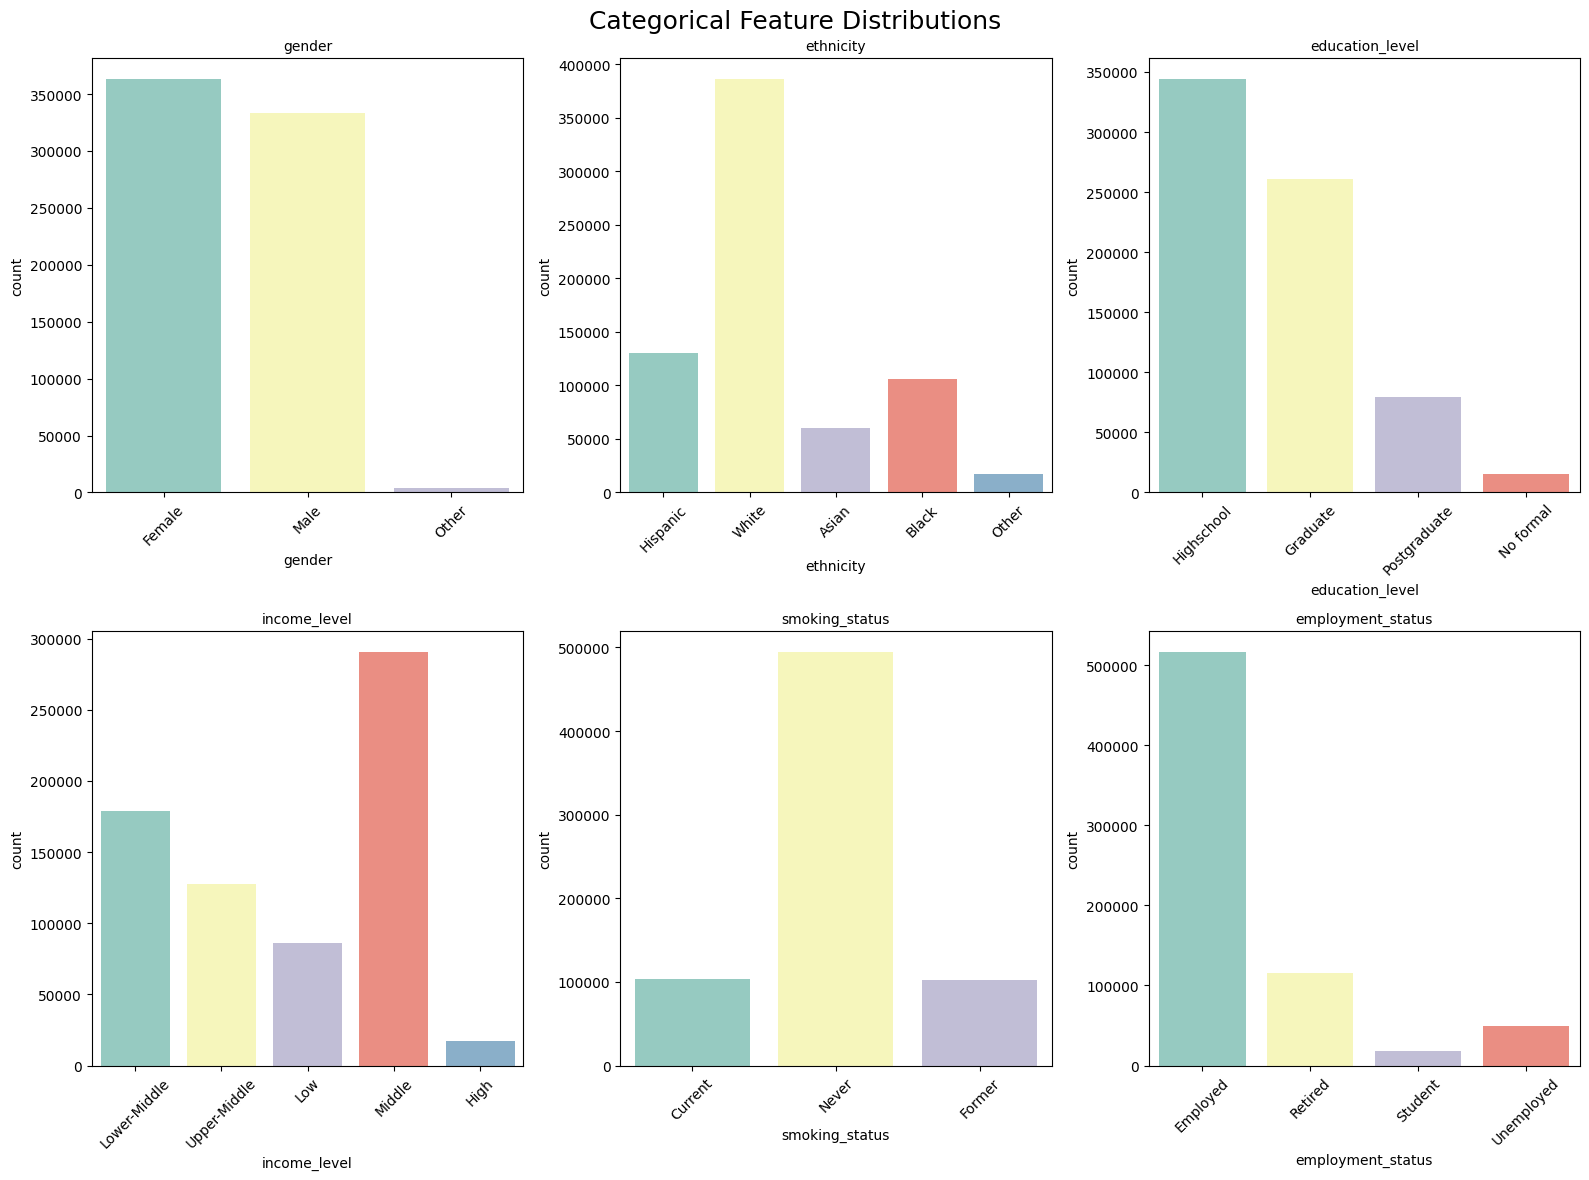

In [22]:
# -----------------------------
# Categorical Feature Distributions
# -----------------------------
print("\n===== CATEGORICAL FEATURE DISTRIBUTIONS =====")

fig, axes = plt.subplots(2, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, data=train_df, ax=axes[i], palette="Set3")
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis="x", rotation=45)

plt.suptitle("Categorical Feature Distributions", fontsize=18)
plt.tight_layout()
plt.show()

In [20]:
# -----------------------------
# Outlier Detection 
# -----------------------------
print("\n===== OUTLIER DETECTION =====")

# Numeric outliers using IQR
def numeric_iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return int(((series < lower) | (series > upper)).sum())

outlier_report = {}

# Numeric columns
for col in numeric_cols:
    outlier_report[col] = numeric_iqr_outliers(train_df[col])

print("\nNumber of Outliers per Column:")
for col, count in outlier_report.items():
    print(f"{col}: {count}")


===== OUTLIER DETECTION =====

Number of Outliers per Column:
age: 1013
alcohol_consumption_per_week: 509
physical_activity_minutes_per_week: 33490
diet_score: 1997
sleep_hours_per_day: 6152
screen_time_hours_per_day: 2337
bmi: 4254
waist_to_hip_ratio: 6159
systolic_bp: 775
diastolic_bp: 5752
heart_rate: 1797
cholesterol_total: 1771
hdl_cholesterol: 4693
ldl_cholesterol: 2290
triglycerides: 9053
family_history_diabetes: 104581
hypertension_history: 127393
cardiovascular_history: 21227



===== CORRELATION ANALYSIS =====


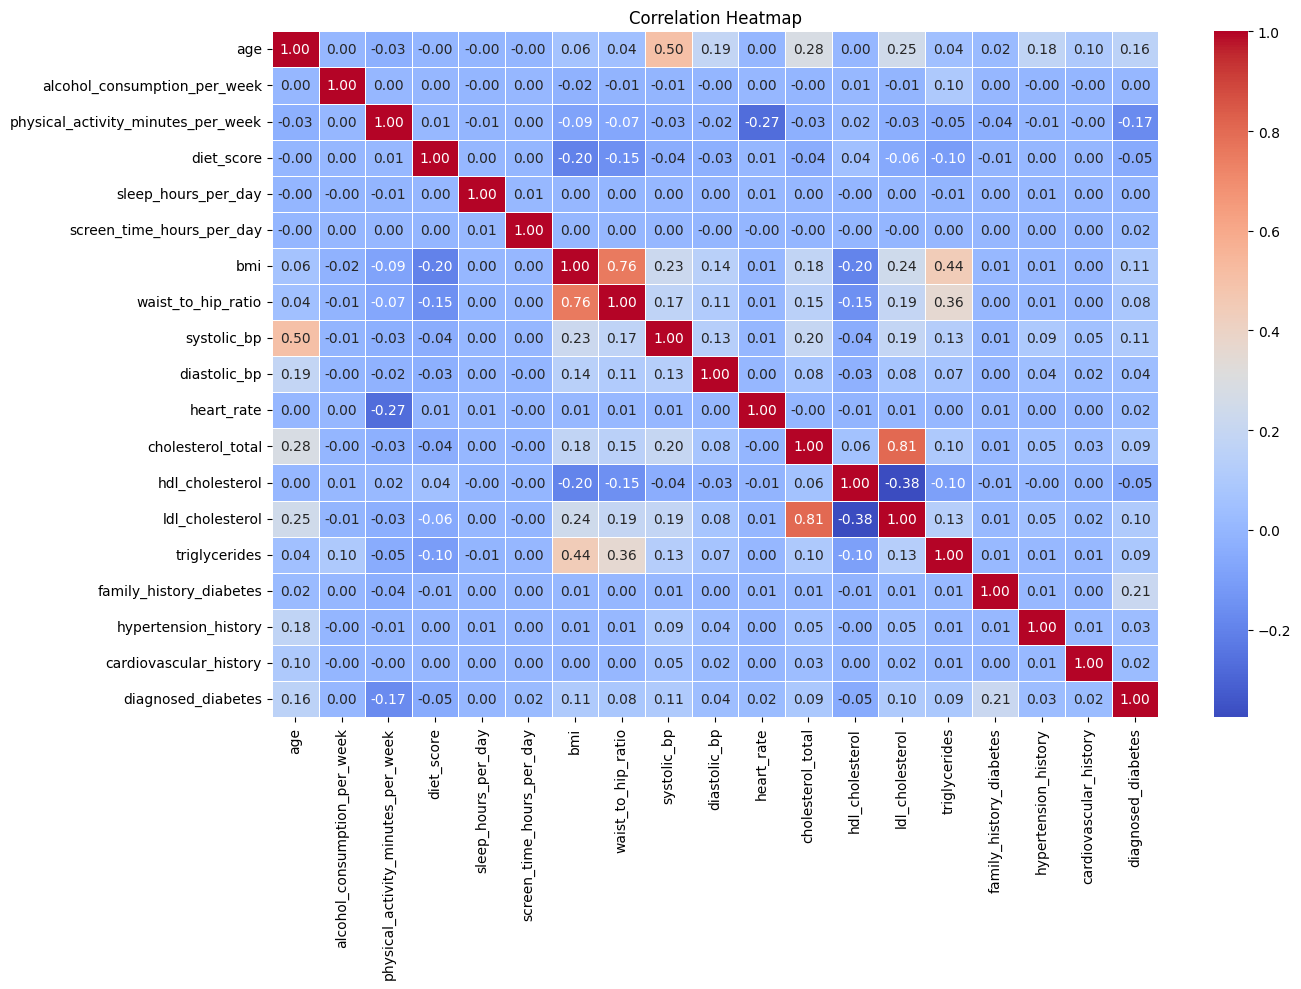

In [18]:
# -----------------------------
# Correlation Analysis
# -----------------------------
print("\n===== CORRELATION ANALYSIS =====")

plt.figure(figsize=(14, 10))
corr = train_df[numeric_cols + ["diagnosed_diabetes"]].corr()

sns.heatmap(
    corr,
    annot=True,          
    fmt=".2f",           
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Data Preprocessing

In [3]:
# Feature and target separation
X = train_df.drop(["id", "diagnosed_diabetes"], axis=1)
y = train_df["diagnosed_diabetes"]

In [4]:
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numeric_columns = X.select_dtypes(exclude=["object"]).columns.tolist()

In [5]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
# Preprocessing pipeline for categorical and numeric data
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_columns),
        ("num", "passthrough", numeric_columns)
    ]
)

## Model training & evaluation

### XGBoost

In [7]:
# XGBoost model pipeline
xgb_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", XGBClassifier(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=7,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'ethnicity',
                                                   'education_level',
                                                   'income_level',
                                                   'smoking_status',
                                                   'employment_status']),
                                                 ('num', 'passthrough',
                                                  ['age',
                                                   'alcohol_consumption_per_week',
                                                   'physical_activity_minutes_per_week',
                                                   'diet_score',
                                                   'sleep_hours_per_day',
                                                   'scr...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.03,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=600, n_jobs=-1,
                               num_parallel_tree=None, random_state=42, ...))])

In [8]:
xgb_train_pred = xgb_pipeline.predict(X_train)
xgb_test_pred = xgb_pipeline.predict(X_test)

xgb_test_proba = xgb_pipeline.predict_proba(X_test)[:, 1]
xgb_auc = roc_auc_score(y_test, xgb_test_proba)

print("\n===== XGBoost Results =====")
print(f"Training Accuracy: {accuracy_score(y_train, xgb_train_pred):.4f}")
print(f"Testing Accuracy: {accuracy_score(y_test, xgb_test_pred):.4f}")
print(f"ROC-AUC Score: {xgb_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, xgb_test_pred))


===== XGBoost Results =====
Training Accuracy: 0.6987
Testing Accuracy: 0.6827
ROC-AUC Score: 0.7241

Classification Report:
              precision    recall  f1-score   support

         0.0       0.62      0.42      0.50     52739
         1.0       0.70      0.84      0.77     87261

    accuracy                           0.68    140000
   macro avg       0.66      0.63      0.63    140000
weighted avg       0.67      0.68      0.67    140000



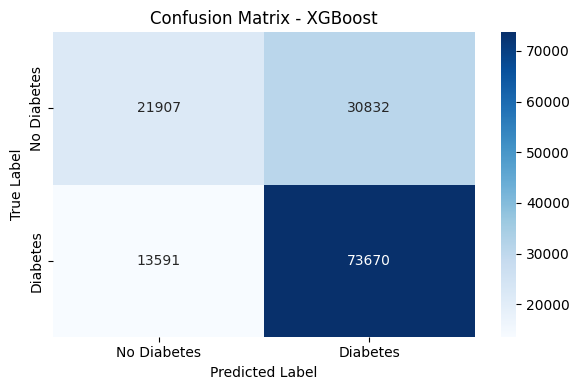

In [9]:
cm_xgb = confusion_matrix(y_test, xgb_test_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

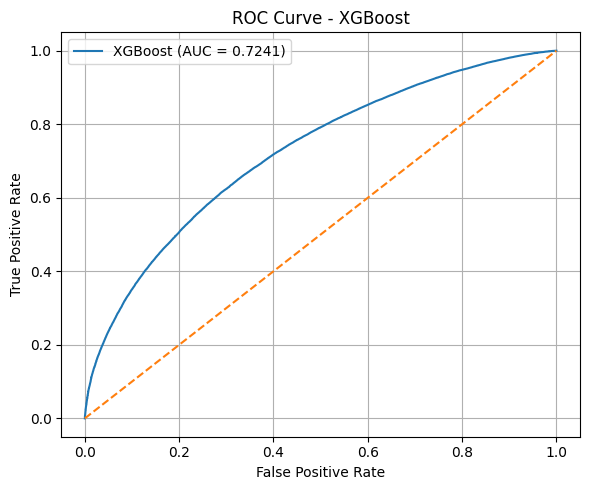

In [10]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, xgb_test_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {xgb_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 1. Decision Tree

In [11]:
dt_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", DecisionTreeClassifier(
        max_depth=6,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

dt_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'ethnicity',
                                                   'education_level',
                                                   'income_level',
                                                   'smoking_status',
                                                   'employment_status']),
                                                 ('num', 'passthrough',
                                                  ['age',
                                                   'alcohol_consumption_per_week',
                                                   'physical_activity_minutes_per_week',
                                                   'diet_score',
                                                   'sleep_hours_per_day',
                                                   'screen_time_hours_per_day',
                                                   'bmi', 'waist_to_hip_ratio',
                                                   'systolic_bp',
                                                   'diastolic_bp', 'heart_rate',
                                                   'cholesterol_total',
                                                   'hdl_cholesterol',
                                                   'ldl_cholesterol',
                                                   'triglycerides',
                                                   'family_history_diabetes',
                                                   'hypertension_history',
                                                   'cardiovascular_history'])])),
                ('model',
                 DecisionTreeClassifier(max_depth=6, min_samples_leaf=5,
                                        min_samples_split=10,
                                        random_state=42))])

In [14]:
dt_train_pred = dt_pipeline.predict(X_train)
dt_test_pred = dt_pipeline.predict(X_test)

dt_test_proba = dt_pipeline.predict_proba(X_test)[:, 1]
dt_auc = roc_auc_score(y_test, dt_test_proba)

print("\n===== Decision Tree Results =====")
print(f"Training Accuracy: {accuracy_score(y_train, dt_train_pred):.4f}")
print(f"Testing Accuracy: {accuracy_score(y_test, dt_test_pred):.4f}")
print(f"ROC-AUC Score: {dt_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, dt_test_pred))


===== Decision Tree Results =====
Training Accuracy: 0.6608
Testing Accuracy: 0.6611
ROC-AUC Score: 0.6860

Classification Report:
              precision    recall  f1-score   support

         0.0       0.60      0.30      0.40     52739
         1.0       0.67      0.88      0.76     87261

    accuracy                           0.66    140000
   macro avg       0.64      0.59      0.58    140000
weighted avg       0.65      0.66      0.63    140000



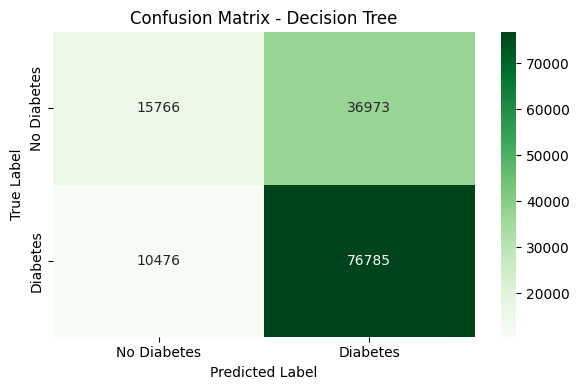

In [15]:
cm_dt = confusion_matrix(y_test, dt_test_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

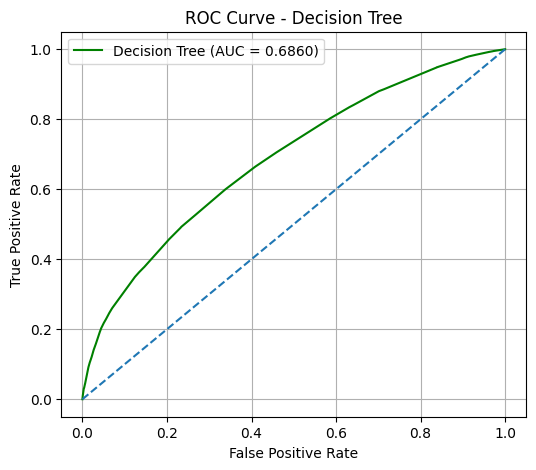

In [16]:
fpr, tpr, _ = roc_curve(y_test, dt_test_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {dt_auc:.4f})", color="green")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve - Decision Tree")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### 3. Random Forest

In [17]:
rf_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'ethnicity',
                                                   'education_level',
                                                   'income_level',
                                                   'smoking_status',
                                                   'employment_status']),
                                                 ('num', 'passthrough',
                                                  ['age',
                                                   'alcohol_consumption_per_week',
                                                   'physical_activity_minutes_per_week',
                                                   'diet_score',
                                                   'sleep_hours_per_day',
                                                   'scr...
                                                   'bmi', 'waist_to_hip_ratio',
                                                   'systolic_bp',
                                                   'diastolic_bp', 'heart_rate',
                                                   'cholesterol_total',
                                                   'hdl_cholesterol',
                                                   'ldl_cholesterol',
                                                   'triglycerides',
                                                   'family_history_diabetes',
                                                   'hypertension_history',
                                                   'cardiovascular_history'])])),
                ('model',
                 RandomForestClassifier(max_depth=10, min_samples_leaf=3,
                                        min_samples_split=5, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [18]:
rf_train_pred = rf_pipeline.predict(X_train)
rf_test_pred = rf_pipeline.predict(X_test)

rf_test_proba = rf_pipeline.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_test_proba)

print("\n===== Random Forest Results =====")
print(f"Training Accuracy: {accuracy_score(y_train, rf_train_pred):.4f}")
print(f"Testing Accuracy: {accuracy_score(y_test, rf_test_pred):.4f}")
print(f"ROC-AUC Score: {rf_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, rf_test_pred))


===== Random Forest Results =====
Training Accuracy: 0.6699
Testing Accuracy: 0.6653
ROC-AUC Score: 0.6988

Classification Report:
              precision    recall  f1-score   support

         0.0       0.63      0.28      0.39     52739
         1.0       0.67      0.90      0.77     87261

    accuracy                           0.67    140000
   macro avg       0.65      0.59      0.58    140000
weighted avg       0.66      0.67      0.63    140000



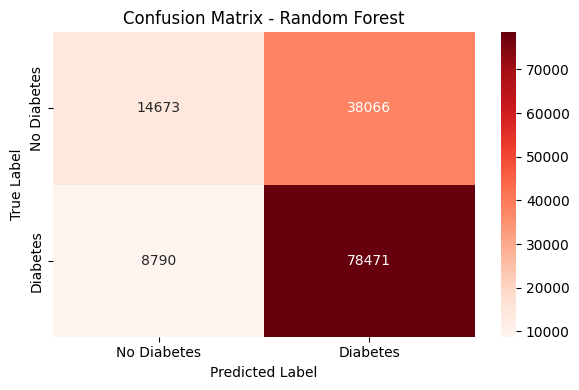

In [19]:
cm_rf = confusion_matrix(y_test, rf_test_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

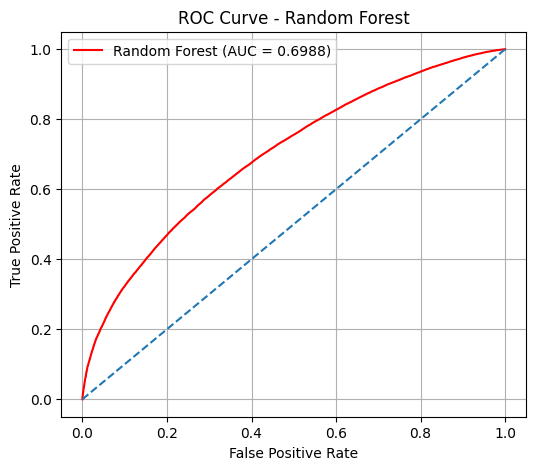

In [20]:
fpr, tpr, _ = roc_curve(y_test, rf_test_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {rf_auc:.4f})", color="red")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### 4. Logistic Regression

In [21]:
preprocess_lr = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_columns),
        ("num", StandardScaler(), numeric_columns)
    ]
)

lr_pipeline = Pipeline([
    ("preprocess", preprocess_lr),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'ethnicity',
                                                   'education_level',
                                                   'income_level',
                                                   'smoking_status',
                                                   'employment_status']),
                                                 ('num', StandardScaler(),
                                                  ['age',
                                                   'alcohol_consumption_per_week',
                                                   'physical_activity_minutes_per_week',
                                                   'diet_score',
                                                   'sleep_hours_per_day',
                                                   'screen_time_hours_per_day',
                                                   'bmi', 'waist_to_hip_ratio',
                                                   'systolic_bp',
                                                   'diastolic_bp', 'heart_rate',
                                                   'cholesterol_total',
                                                   'hdl_cholesterol',
                                                   'ldl_cholesterol',
                                                   'triglycerides',
                                                   'family_history_diabetes',
                                                   'hypertension_history',
                                                   'cardiovascular_history'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [22]:
lr_train_pred = lr_pipeline.predict(X_train)
lr_test_pred = lr_pipeline.predict(X_test)

lr_test_proba = lr_pipeline.predict_proba(X_test)[:, 1]
lr_auc = roc_auc_score(y_test, lr_test_proba)

print("\n===== Logistic Regression Results =====")
print(f"Training Accuracy: {accuracy_score(y_train, lr_train_pred):.4f}")
print(f"Testing Accuracy: {accuracy_score(y_test, lr_test_pred):.4f}")
print(f"ROC-AUC Score: {lr_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, lr_test_pred))


===== Logistic Regression Results =====
Training Accuracy: 0.6633
Testing Accuracy: 0.6641
ROC-AUC Score: 0.6948

Classification Report:
              precision    recall  f1-score   support

         0.0       0.60      0.33      0.43     52739
         1.0       0.68      0.86      0.76     87261

    accuracy                           0.66    140000
   macro avg       0.64      0.60      0.60    140000
weighted avg       0.65      0.66      0.64    140000



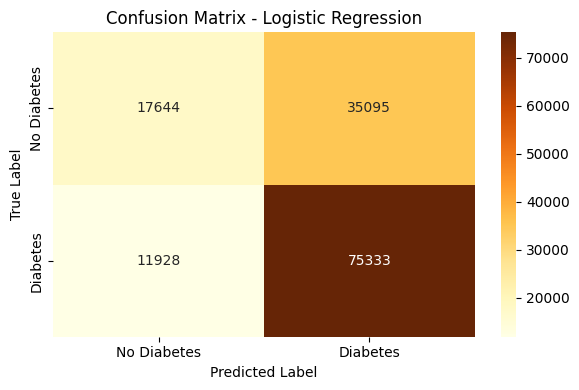

In [23]:
cm_lr = confusion_matrix(y_test, lr_test_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="YlOrBr",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

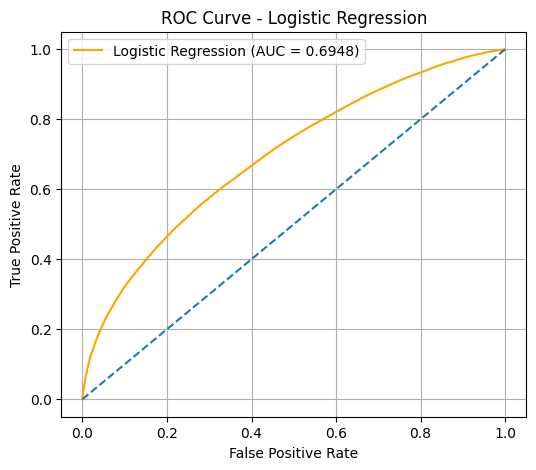

In [24]:
fpr, tpr, _ = roc_curve(y_test, lr_test_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {lr_auc:.4f})", color="orange")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### 5. Multilayer Perceptron - ANN

In [25]:
# Preprocessing Pipeline
mlp_preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_columns),
        ("num", StandardScaler(), numeric_columns)
    ]
)

# MLP (ANN) Pipeline
mlp_pipeline = Pipeline([
    ("preprocess", mlp_preprocess),
    ("model", MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0005,
        learning_rate="adaptive",
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=42
    ))
])

# Train the Model
mlp_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'ethnicity',
                                                   'education_level',
                                                   'income_level',
                                                   'smoking_status',
                                                   'employment_status']),
                                                 ('num', StandardScaler(),
                                                  ['age',
                                                   'alcohol_consumption_per_week',
                                                   'physical_activity_minutes_per_week',
                                                   'diet_score',
                                                   'sleep_hours_per_day',
                                                   '...
                                                   'systolic_bp',
                                                   'diastolic_bp', 'heart_rate',
                                                   'cholesterol_total',
                                                   'hdl_cholesterol',
                                                   'ldl_cholesterol',
                                                   'triglycerides',
                                                   'family_history_diabetes',
                                                   'hypertension_history',
                                                   'cardiovascular_history'])])),
                ('model',
                 MLPClassifier(alpha=0.0005, early_stopping=True,
                               hidden_layer_sizes=(128, 64, 32),
                               learning_rate='adaptive', max_iter=500,
                               n_iter_no_change=15, random_state=42))])

In [26]:
# Predictions
mlp_train_pred = mlp_pipeline.predict(X_train)
mlp_test_pred = mlp_pipeline.predict(X_test)

# Probabilities for ROC-AUC
mlp_test_proba = mlp_pipeline.predict_proba(X_test)[:, 1]
mlp_auc = roc_auc_score(y_test, mlp_test_proba)

# Results
print("\n===== Multilayer Perceptron Results =====")
print(f"Training Accuracy: {accuracy_score(y_train, mlp_train_pred):.4f}")
print(f"Testing Accuracy: {accuracy_score(y_test, mlp_test_pred):.4f}")
print(f"ROC-AUC Score: {mlp_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, mlp_test_pred))


===== Multilayer Perceptron Results =====
Training Accuracy: 0.6657
Testing Accuracy: 0.6651
ROC-AUC Score: 0.6950

Classification Report:
              precision    recall  f1-score   support

         0.0       0.59      0.35      0.44     52739
         1.0       0.69      0.85      0.76     87261

    accuracy                           0.67    140000
   macro avg       0.64      0.60      0.60    140000
weighted avg       0.65      0.67      0.64    140000



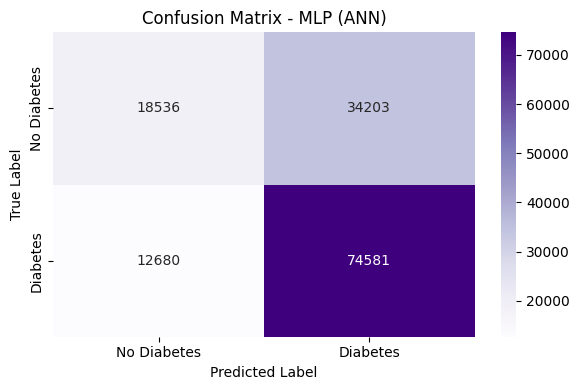

In [43]:
# Confusion Matrix
cm = confusion_matrix(y_test, mlp_test_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.title("Confusion Matrix - MLP (ANN)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

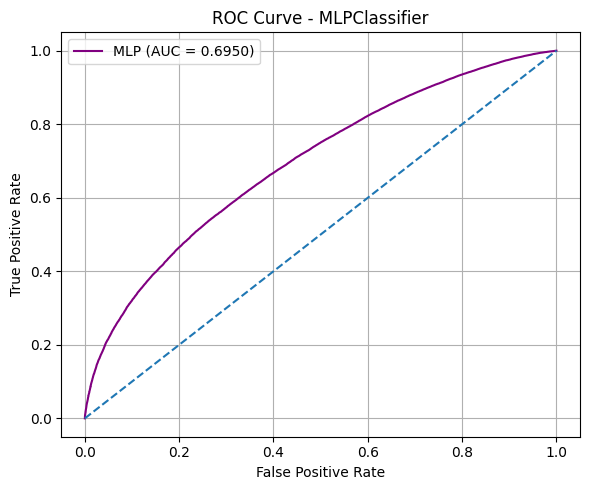

In [44]:
from sklearn.metrics import roc_curve, roc_auc_score

# Compute ROC-AUC
mlp_auc = roc_auc_score(y_test, mlp_test_proba)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, mlp_test_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"MLP (AUC = {mlp_auc:.4f})", color="purple")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - MLPClassifier")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Model comparison 

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

In [30]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Probabilities for ROC-AUC
    y_test_proba = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Training Accuracy": accuracy_score(y_train, y_train_pred),
        "Testing Accuracy": accuracy_score(y_test, y_test_pred),
        "ROC-AUC Score": roc_auc_score(y_test, y_test_proba),
        "Precision": precision_score(y_test, y_test_pred),
        "Recall": recall_score(y_test, y_test_pred),
        "F1 Score": f1_score(y_test, y_test_pred)
    }

In [33]:
models = {
    "XGBoost": xgb_pipeline,
    "Random Forest": rf_pipeline,
    "Decision Tree": dt_pipeline,
    "Logistic Regression": lr_pipeline,
    "Multilayer Perceptron": mlp_pipeline
}

results = []

for name, model in models.items():
    results.append(
        evaluate_model(
            name, model,
            X_train, y_train,
            X_test, y_test
        )
    )

metrics_df = pd.DataFrame(results)

In [34]:
# Sort by Testing Accuracy (Descending)
metrics_df = metrics_df.sort_values(
    by="Testing Accuracy",
    ascending=False
).reset_index(drop=True)

# Display summary table
metrics_df.style.format({
    "Training Accuracy": "{:.4f}",
    "Testing Accuracy": "{:.4f}",
    "ROC-AUC Score": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}"
})

,Model,Training Accuracy,Testing Accuracy,ROC-AUC Score,Precision,Recall,F1 Score
0,XGBoost,0.6987,0.6827,0.7241,0.7050,0.8442,0.7683
1,Random Forest,0.6699,0.6653,0.6988,0.6734,0.8993,0.7701
2,Multilayer Perceptron,0.6657,0.6651,0.6950,0.6856,0.8547,0.7609
3,Logistic Regression,0.6633,0.6641,0.6948,0.6822,0.8633,0.7621
4,Decision Tree,0.6608,0.6611,0.6860,0.6750,0.8799,0.7640


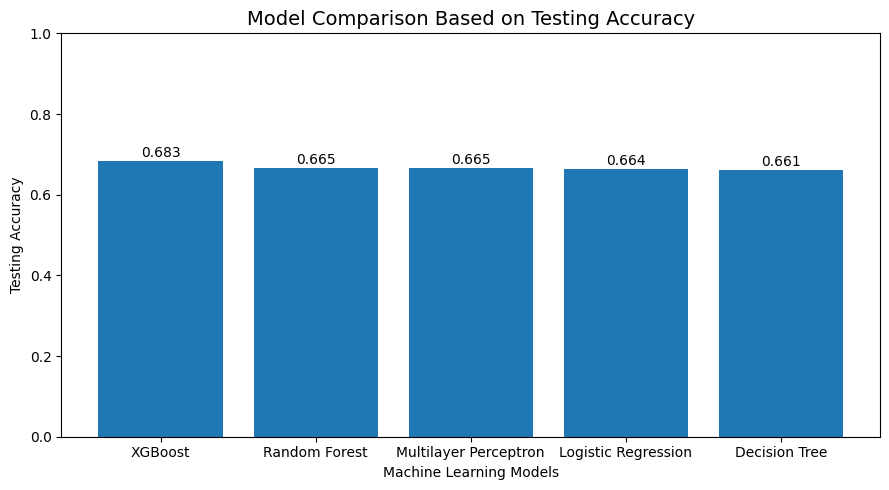

In [35]:
plt.figure(figsize=(9, 5))

plt.bar(
    metrics_df["Model"],
    metrics_df["Testing Accuracy"]
)

plt.title("Model Comparison Based on Testing Accuracy", fontsize=14)
plt.xlabel("Machine Learning Models")
plt.ylabel("Testing Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(metrics_df["Testing Accuracy"]):
    plt.text(i, value + 0.01, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

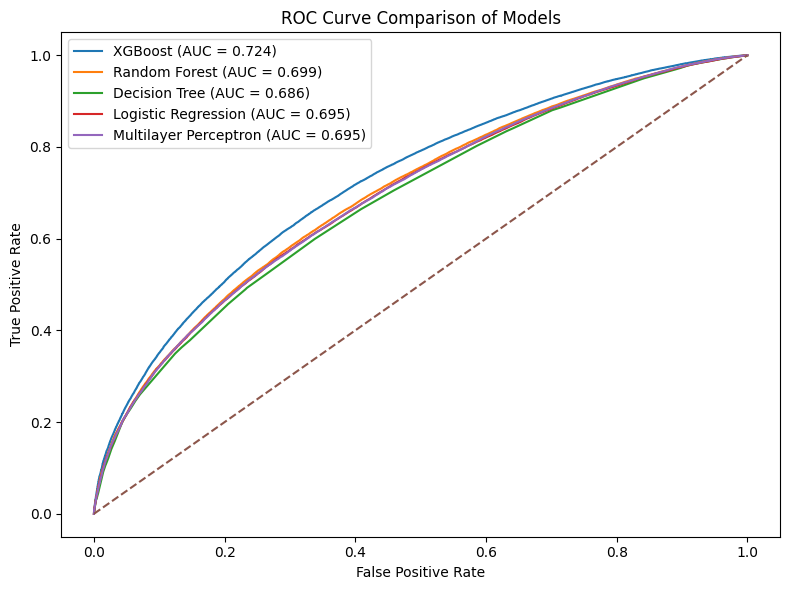

In [36]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_test_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_test_proba)
    auc = roc_auc_score(y_test, y_test_proba)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Models")
plt.legend()
plt.tight_layout()
plt.show()

### Predict on the test dataset

In [44]:
X_test_final = test_df.drop("id", axis=1)

test_proba = xgb_pipeline.predict_proba(X_test_final)[:, 1]

submission = pd.DataFrame({
    "id": test_df["id"],
    "diagnosed_diabetes": test_proba
})

submission.to_csv("submission.csv", index=False)
print("✅ Kaggle submission file created")

✅ Kaggle submission file created


### Save Model as Pickle File

In [45]:
import joblib

# Build metadata for UI
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numeric_columns = X.select_dtypes(exclude=["object"]).columns.tolist()

# Identify categorical and numeric columns
cat_options = {c: sorted(X[c].dropna().unique().tolist()) for c in categorical_columns}
num_bounds = {c: (float(X[c].min()), float(X[c].max())) for c in numeric_columns}
num_defaults = {c: float(X[c].mean()) for c in numeric_columns}

bundle = {
    "pipeline": xgb_pipeline,
    "categorical_columns": categorical_columns,
    "numeric_columns": numeric_columns,
    "cat_options": cat_options,
    "num_bounds": num_bounds,
    "num_defaults": num_defaults
}

joblib.dump(bundle, "xgb_model.pkl")
print("✅ Saved")

✅ Saved
